In [1]:
import warnings
warnings.filterwarnings('ignore')
 
import numpy as np
import pandas as pd
 
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
 
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
 
import joblib
 
# Plot settings
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
sns.set_theme(style='whitegrid')

In [2]:
df=pd.read_csv(r"C:\Users\riaka\Downloads\online_gaming_behavior_dataset.csv")

In [3]:
df.info

<bound method DataFrame.info of        PlayerID  Age  Gender Location   GameGenre  PlayTimeHours  \
0          9000   43    Male    Other    Strategy      16.271119   
1          9001   29  Female      USA    Strategy       5.525961   
2          9002   22  Female      USA      Sports       8.223755   
3          9003   35    Male      USA      Action       5.265351   
4          9004   33    Male   Europe      Action      15.531945   
...         ...  ...     ...      ...         ...            ...   
40029     49029   32    Male      USA    Strategy      20.619662   
40030     49030   44  Female    Other  Simulation      13.539280   
40031     49031   15  Female      USA         RPG       0.240057   
40032     49032   34    Male      USA      Sports      14.017818   
40033     49033   19    Male      USA      Sports      10.083804   

       InGamePurchases GameDifficulty  SessionsPerWeek  \
0                    0         Medium                6   
1                    0         Medi

In [4]:
df.shape

(40034, 13)

In [5]:
df.describe()

,PlayerID,Age,PlayTimeHours,InGamePurchases,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked
count,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000
mean,29016.500000,31.992531,12.024365,0.200854,9.471774,94.792252,49.655568,24.526477
std,11556.964675,10.043227,6.914638,0.400644,5.763667,49.011375,28.588379,14.430726
min,9000.000000,15.000000,0.000115,0.000000,0.000000,10.000000,1.000000,0.000000
25%,19008.250000,23.000000,6.067501,0.000000,4.000000,52.000000,25.000000,12.000000
50%,29016.500000,32.000000,12.008002,0.000000,9.000000,95.000000,49.000000,25.000000
75%,39024.750000,41.000000,17.963831,0.000000,14.000000,137.000000,74.000000,37.000000
max,49033.000000,49.000000,23.999592,1.000000,19.000000,179.000000,99.000000,49.000000


In [6]:
df.describe(include='all')

,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
count,40034.000000,40034.000000,40034,40034,40034,40034.000000,40034.000000,40034,40034.000000,40034.000000,40034.000000,40034.000000,40034
unique,NaN,NaN,2,4,5,NaN,NaN,3,NaN,NaN,NaN,NaN,3
top,NaN,NaN,Male,USA,Sports,NaN,NaN,Easy,NaN,NaN,NaN,NaN,Medium
freq,NaN,NaN,23959,16000,8048,NaN,NaN,20015,NaN,NaN,NaN,NaN,19374
mean,29016.500000,31.992531,NaN,NaN,NaN,12.024365,0.200854,NaN,9.471774,94.792252,49.655568,24.526477,NaN
std,11556.964675,10.043227,NaN,NaN,NaN,6.914638,0.400644,NaN,5.763667,49.011375,28.588379,14.430726,NaN
min,9000.000000,15.000000,NaN,NaN,NaN,0.000115,0.000000,NaN,0.000000,10.000000,1.000000,0.000000,NaN
25%,19008.250000,23.000000,NaN,NaN,NaN,6.067501,0.000000,NaN,4.000000,52.000000,25.000000,12.000000,NaN
50%,29016.500000,32.000000,NaN,NaN,NaN,12.008002,0.000000,NaN,9.000000,95.000000,49.000000,25.000000,NaN
75%,39024.750000,41.000000,NaN,NaN,NaN,17.963831,0.000000,NaN,14.000000,137.000000,74.000000,37.000000,NaN


In [7]:
df['EngagementLevel'].value_counts()

EngagementLevel
Medium    19374
High      10336
Low       10324
Name: count, dtype: int64

In [8]:
df.isnull().sum()

PlayerID                     0
Age                          0
Gender                       0
Location                     0
GameGenre                    0
PlayTimeHours                0
InGamePurchases              0
GameDifficulty               0
SessionsPerWeek              0
AvgSessionDurationMinutes    0
PlayerLevel                  0
AchievementsUnlocked         0
EngagementLevel              0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

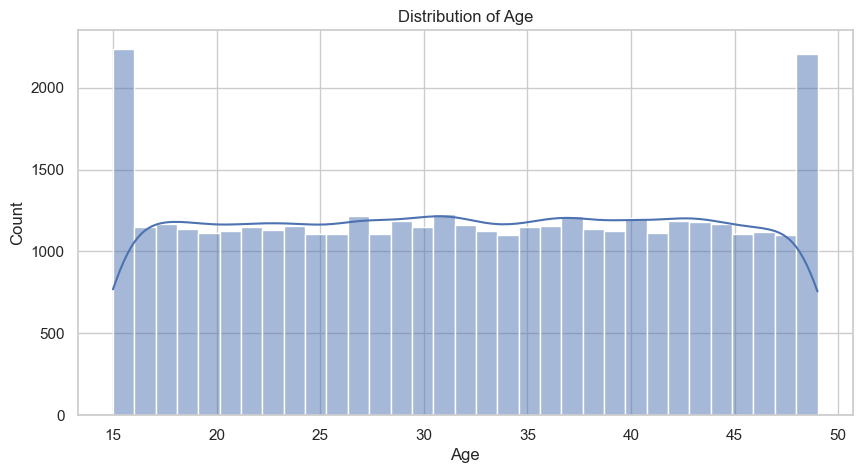

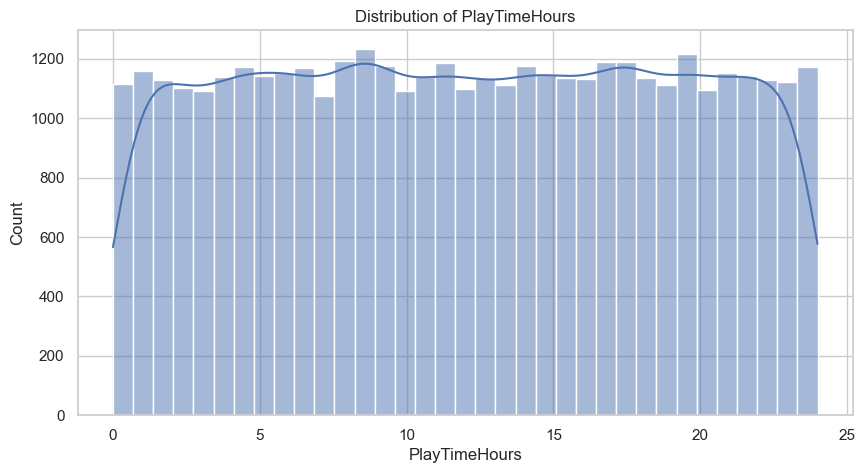

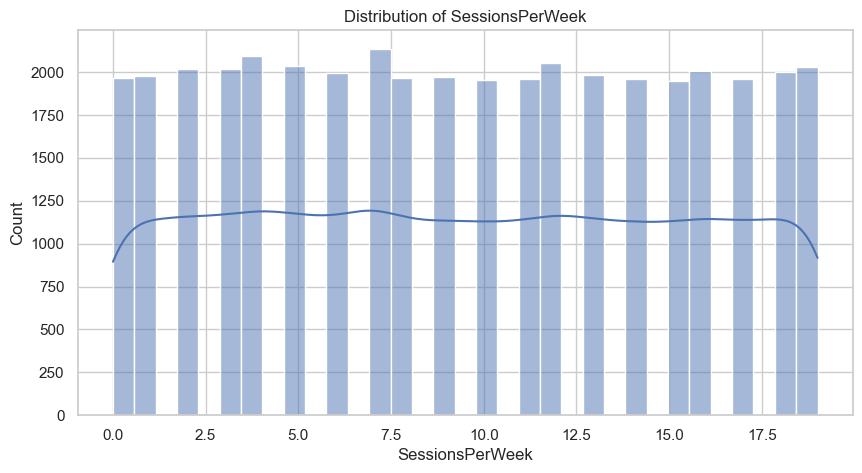

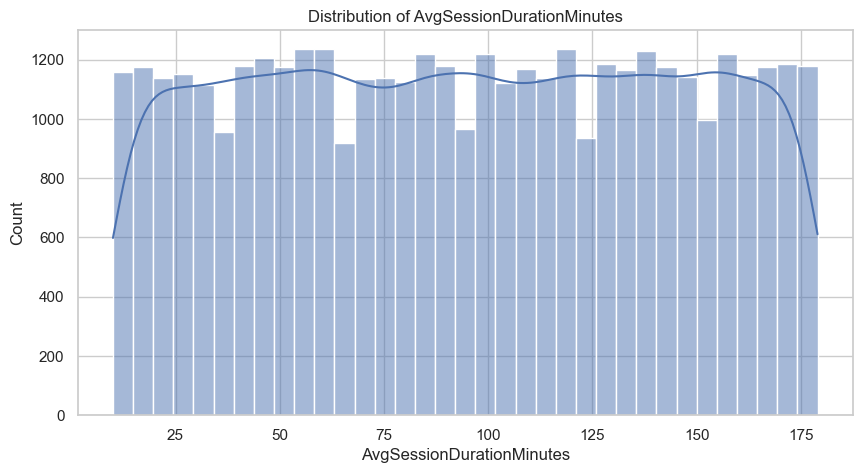

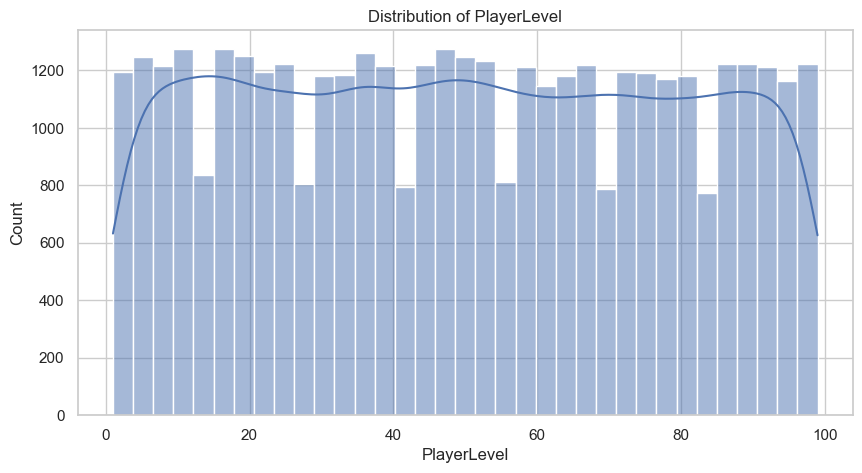

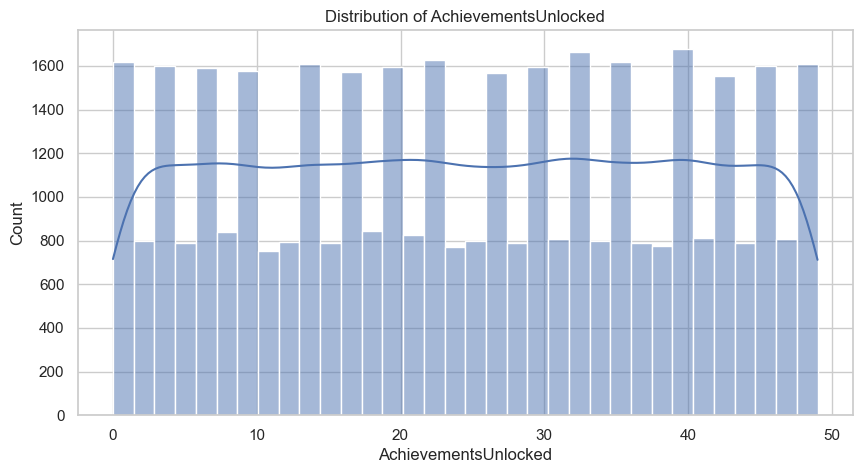

In [10]:
numeric_cols = [
    'Age', 'PlayTimeHours', 'SessionsPerWeek', 'AvgSessionDurationMinutes',
    'PlayerLevel', 'AchievementsUnlocked'
]
 
for col in numeric_cols:
    plt.figure()
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

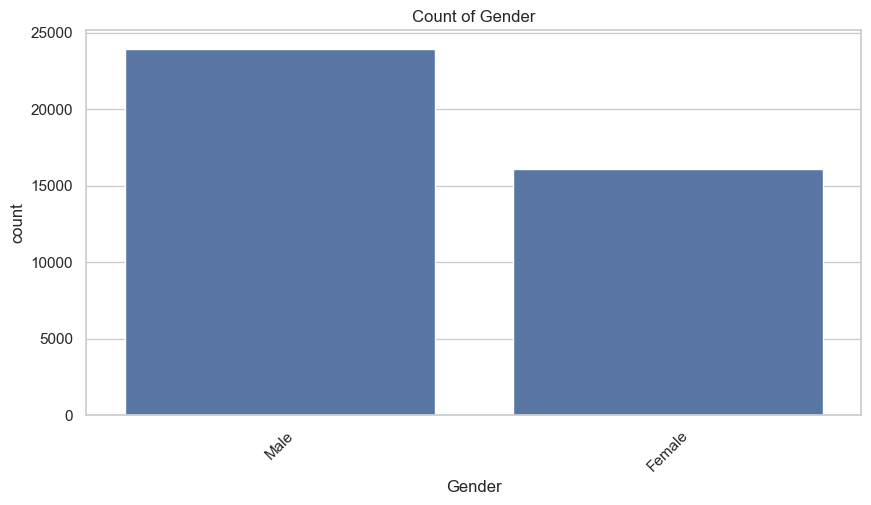

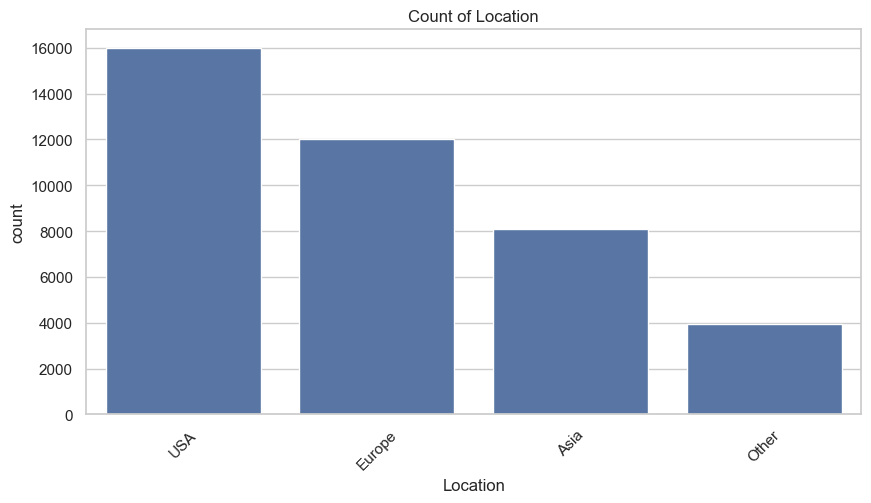

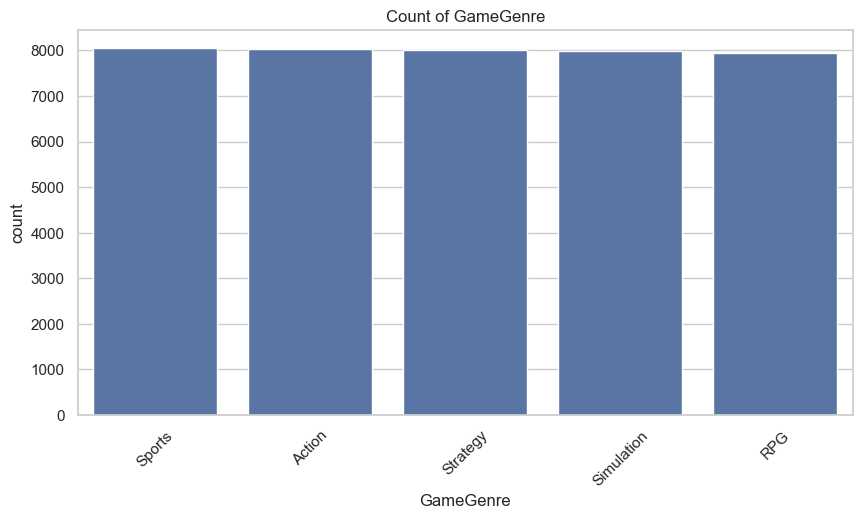

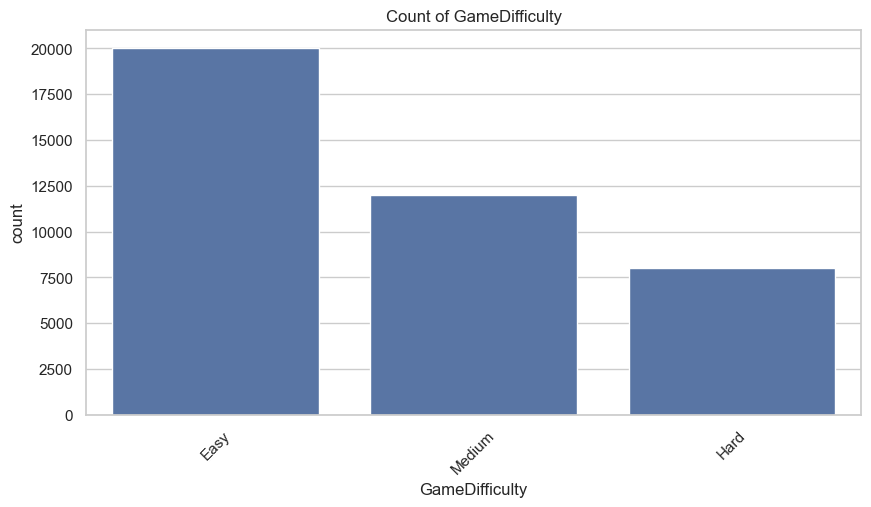

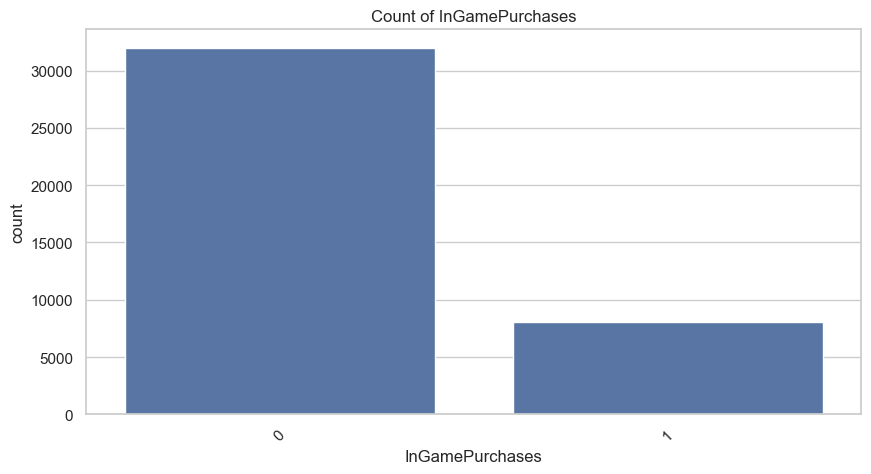

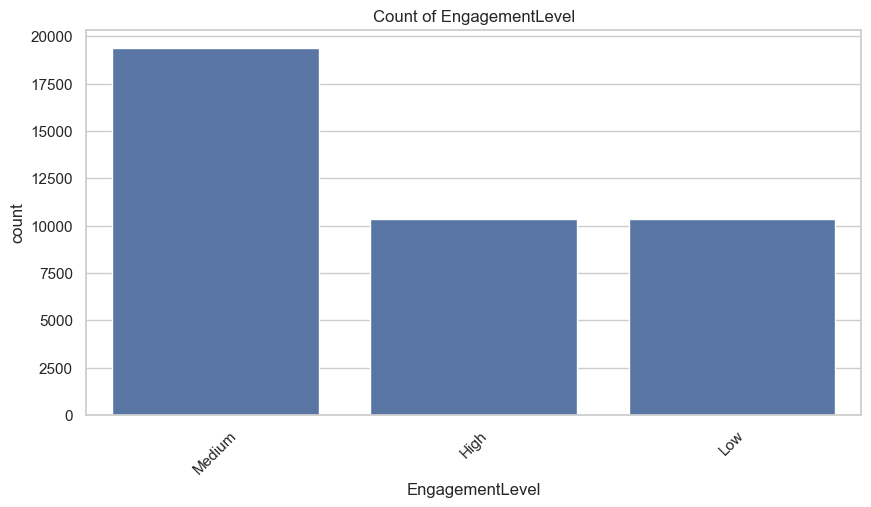

In [11]:
cat_cols = ['Gender', 'Location', 'GameGenre', 'GameDifficulty', 'InGamePurchases', 'EngagementLevel']
 
for col in cat_cols:
    plt.figure()
    sns.countplot(data=df, x=col, order=df[col].value_counts().index)
    plt.title(f'Count of {col}')
    plt.xticks(rotation=45)
    plt.show()

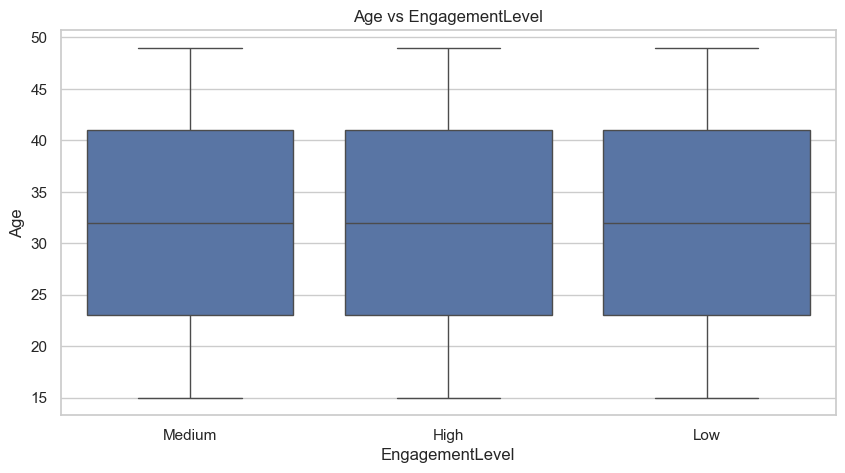

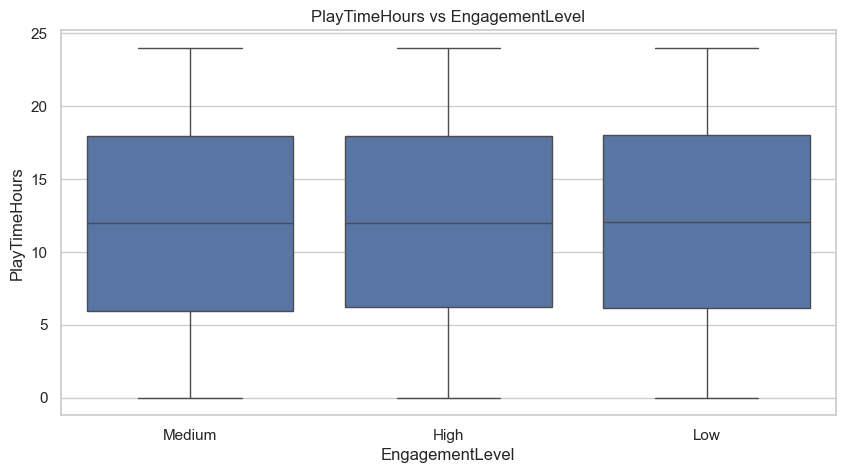

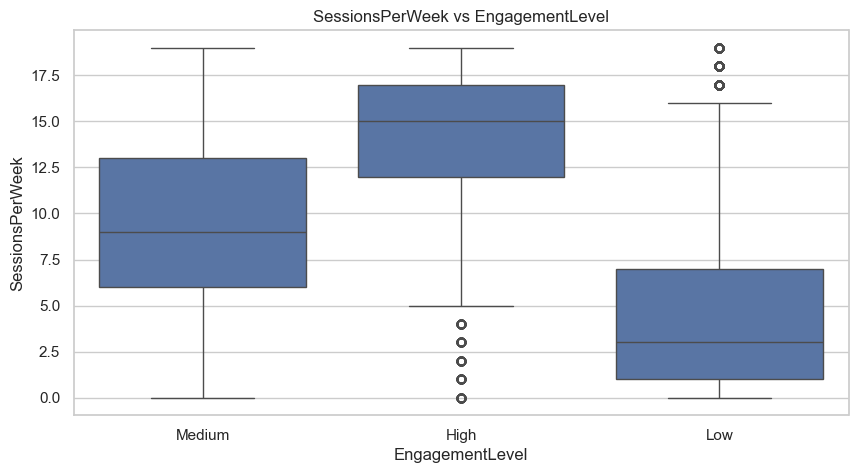

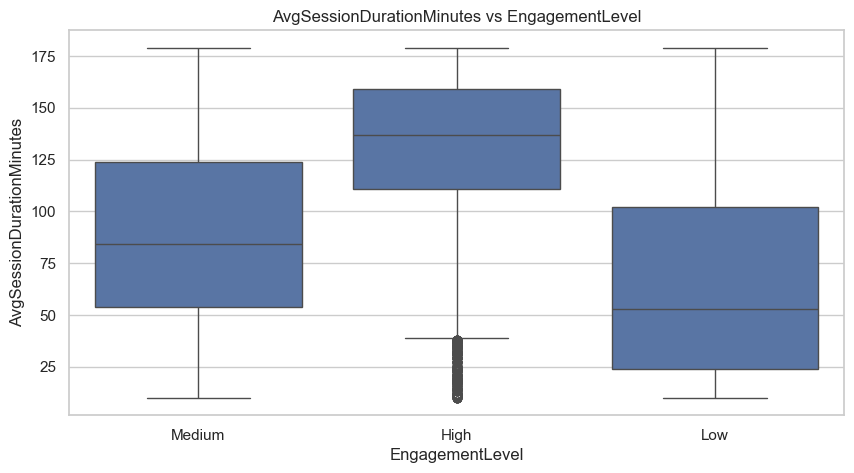

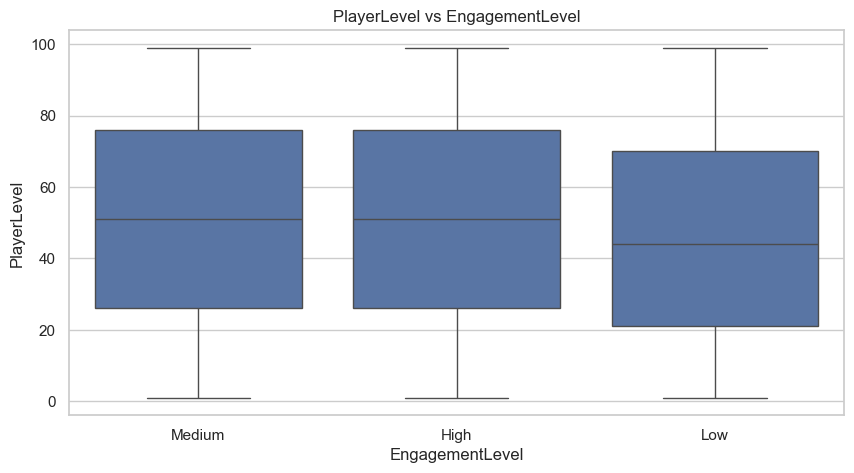

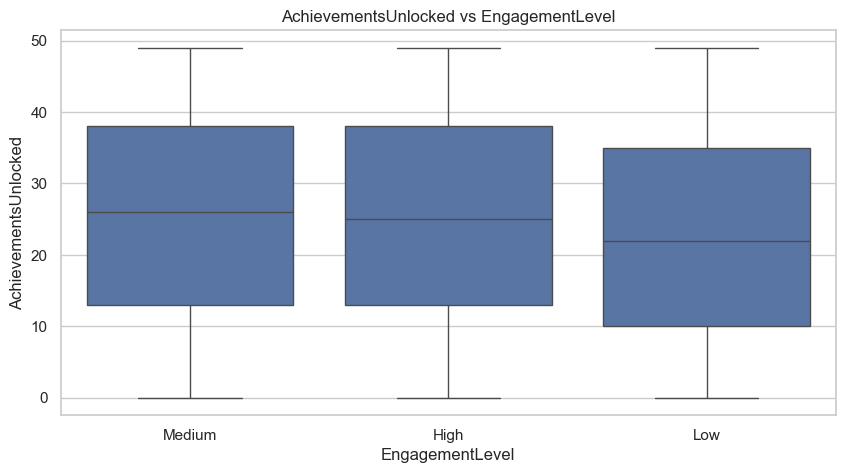

In [12]:
for col in numeric_cols:
    plt.figure()
    sns.boxplot(data=df, x='EngagementLevel', y=col)
    plt.title(f'{col} vs EngagementLevel')
    plt.show()

<Axes: >

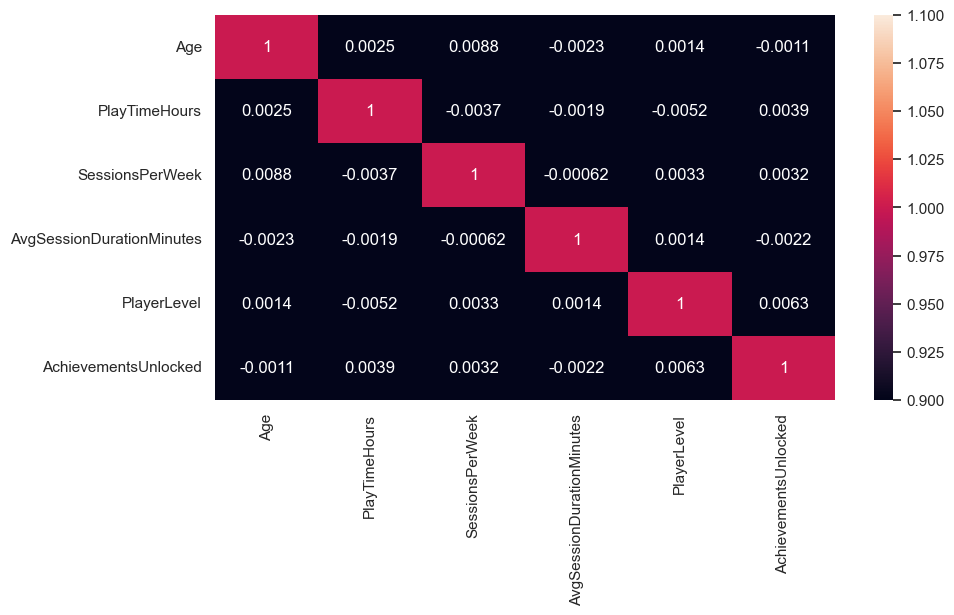

In [13]:
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True,vmax=1,vmin=1)

In [14]:
df_model = df.drop(columns=['PlayerID'])

X = df_model.drop(columns=['EngagementLevel'])
y = df_model['EngagementLevel']

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Train:',X_train.shape,'| Test:',X_test.shape)
print('y_train:',y_train.shape,'Y_test:',y_test.shape)

Train: (32027, 11) | Test: (8007, 11)
y_train: (32027,) Y_test: (8007,)


In [16]:
X_train_enc = pd.get_dummies(X_train,drop_first=False)
X_test_enc = pd.get_dummies(X_test,drop_first=False)

X_train_enc,X_test_enc = X_train_enc.align(X_test_enc,join='left',axis=1,fill_value=0)

print('encoded train shape:', X_train_enc.shape)
print('encoded train shape:', X_test_enc.shape)

encoded train shape: (32027, 21)
encoded train shape: (8007, 21)


In [17]:
dt_base = DecisionTreeClassifier(random_state=42)

dt_base.fit(X_train_enc,y_train)
y_pred_base = dt_base.predict(X_test_enc)

print('Accuracy(Baseline):',accuracy_score(y_test,y_pred_base))

Accuracy(Baseline): 0.8335206694142625


In [18]:
dt_base.get_depth()

33

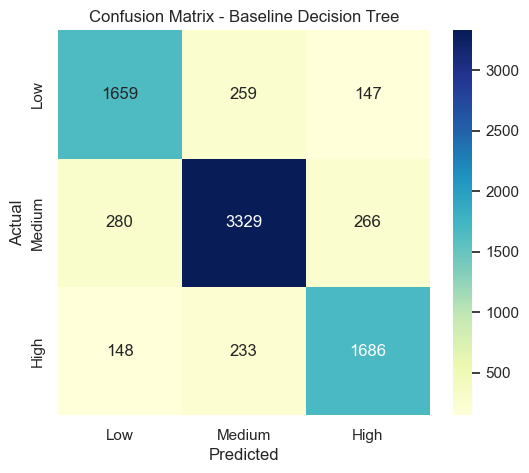

In [19]:
# Confusion matrix (Baseline)
 
cm = confusion_matrix(y_test, y_pred_base, labels=['Low', 'Medium', 'High'])
 
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=['Low','Medium','High'],cmap='YlGnBu', yticklabels=['Low','Medium','High'])
plt.title('Confusion Matrix - Baseline Decision Tree')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()
 

In [20]:
cm

array([[1659,  259,  147],
       [ 280, 3329,  266],
       [ 148,  233, 1686]])

In [21]:
print(classification_report(y_test,y_pred_base))

              precision    recall  f1-score   support

        High       0.80      0.82      0.81      2067
         Low       0.79      0.80      0.80      2065
      Medium       0.87      0.86      0.87      3875

    accuracy                           0.83      8007
   macro avg       0.82      0.83      0.82      8007
weighted avg       0.83      0.83      0.83      8007



In [22]:
dt_base.feature_importances_

array([0.02498986, 0.04290446, 0.00360393, 0.45125696, 0.30600978,
       0.06108527, 0.05992979, 0.00320405, 0.00345862, 0.00425021,
       0.00441773, 0.00204704, 0.00353842, 0.00317356, 0.00384608,
       0.00425079, 0.00404683, 0.00336756, 0.0038747 , 0.00273436,
       0.00400998])

In [23]:
importances = pd.Series(dt_base.feature_importances_,index = X_train_enc.columns)
importances_sorted = importances.sort_values(ascending=False)

importances_sorted.head(22)

SessionsPerWeek              0.451257
AvgSessionDurationMinutes    0.306010
PlayerLevel                  0.061085
AchievementsUnlocked         0.059930
PlayTimeHours                0.042904
Age                          0.024990
Location_Europe              0.004418
GameGenre_Simulation         0.004251
Location_Asia                0.004250
GameGenre_Sports             0.004047
GameDifficulty_Medium        0.004010
GameDifficulty_Easy          0.003875
GameGenre_RPG                0.003846
InGamePurchases              0.003604
Location_USA                 0.003538
Gender_Male                  0.003459
GameGenre_Strategy           0.003368
Gender_Female                0.003204
GameGenre_Action             0.003174
GameDifficulty_Hard          0.002734
Location_Other               0.002047
dtype: float64

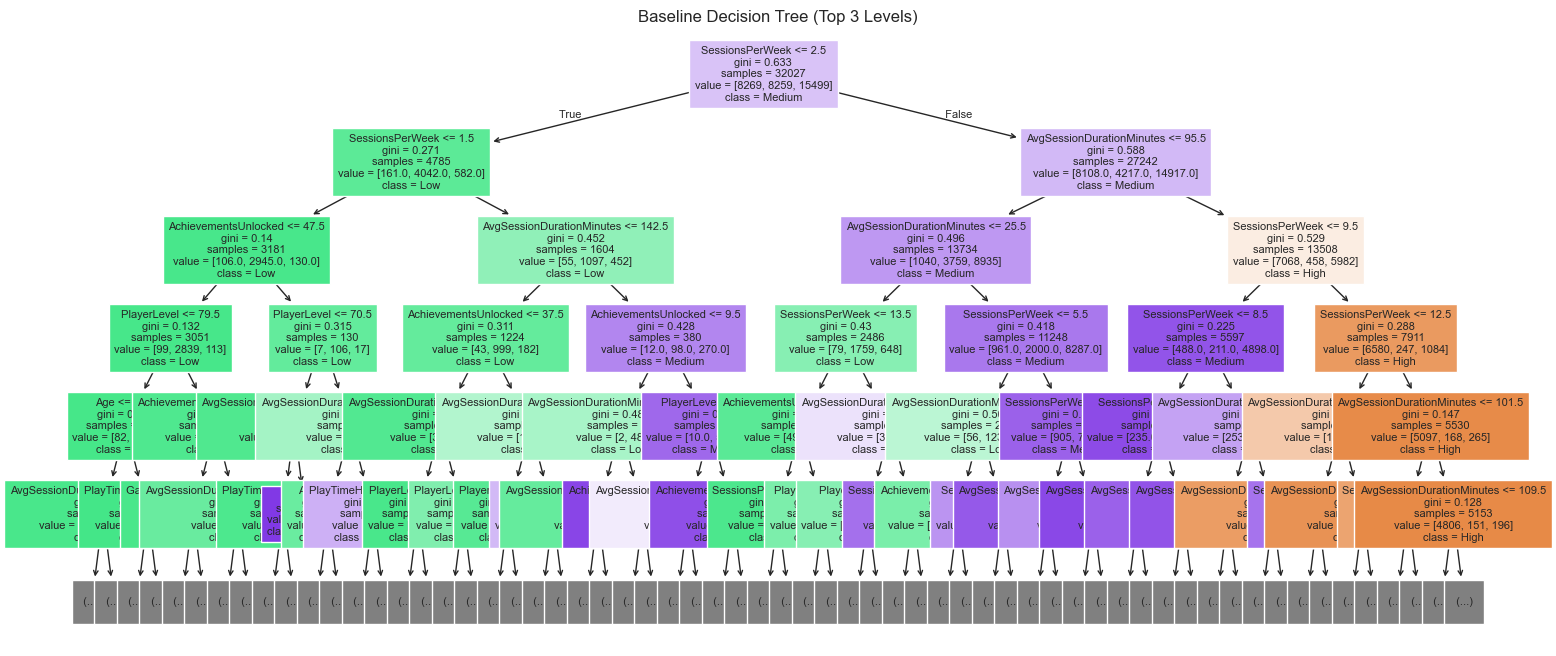

In [24]:
plt.figure(figsize=(18, 8))
plot_tree(
    dt_base,
    feature_names=X_train_enc.columns.tolist(),  
    class_names=dt_base.classes_.tolist(), # Good practice to convert this too
    filled=True,
    max_depth=5,
    fontsize=8
)
plt.title('Baseline Decision Tree (Top 3 Levels)')
plt.show()


In [26]:
from sklearn.tree import export_graphviz
 
dot_data = export_graphviz(
    dt_base,
    out_file=None,
    feature_names=X_train_enc.columns.tolist(),
    class_names=dt_base.classes_.tolist(),
    filled=True,
    rounded=True,
    special_characters=True,
    max_depth=5
)
 
print(dot_data)


digraph Tree {
node [shape=box, style="filled, rounded", color="black", fontname="helvetica"] ;
edge [fontname="helvetica"] ;
0 [label=<SessionsPerWeek &le; 2.5<br/>gini = 0.633<br/>samples = 32027<br/>value = [8269, 8259, 15499]<br/>class = Medium>, fillcolor="#d9c3f7"] ;
1 [label=<SessionsPerWeek &le; 1.5<br/>gini = 0.271<br/>samples = 4785<br/>value = [161.0, 4042.0, 582.0]<br/>class = Low>, fillcolor="#5cea97"] ;
0 -> 1 [labeldistance=2.5, labelangle=45, headlabel="True"] ;
2 [label=<AchievementsUnlocked &le; 47.5<br/>gini = 0.14<br/>samples = 3181<br/>value = [106.0, 2945.0, 130.0]<br/>class = Low>, fillcolor="#48e78b"] ;
1 -> 2 ;
3 [label=<PlayerLevel &le; 79.5<br/>gini = 0.132<br/>samples = 3051<br/>value = [99, 2839, 113]<br/>class = Low>, fillcolor="#47e78a"] ;
2 -> 3 ;
4 [label=<Age &le; 25.5<br/>gini = 0.118<br/>samples = 2483<br/>value = [82, 2330, 71]<br/>class = Low>, fillcolor="#46e789"] ;
3 -> 4 ;
5 [label=<AvgSessionDurationMinutes &le; 121.5<br/>gini = 0.149<br/>sampl

In [28]:
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 8, 12, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10]
}
 
grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
 
grid.fit(X_train_enc, y_train)
 
print('Best Params:', grid.best_params_)
print('Best CV Accuracy:', grid.best_score_)

Best Params: {'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best CV Accuracy: 0.9054548489986578


In [32]:
dt_tuned = grid.best_estimator_
y_pred_tuned = dt_tuned.predict(X_test_enc)

print('Accuracy (Tuned):',accuracy_score(y_test,y_pred_tuned))
print(classification_report(y_test,y_pred_tuned))

Accuracy (Tuned): 0.9023354564755839
              precision    recall  f1-score   support

        High       0.91      0.88      0.89      2067
         Low       0.89      0.87      0.88      2065
      Medium       0.91      0.93      0.92      3875

    accuracy                           0.90      8007
   macro avg       0.90      0.89      0.90      8007
weighted avg       0.90      0.90      0.90      8007



In [33]:
# Create a validation split from training data for pruning selection
 
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train_enc, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)
 
print('Train_sub:', X_train_sub.shape, '| Val:', X_val.shape)

Train_sub: (25621, 21) | Val: (6406, 21)


In [34]:
# Get pruning path from the tuned model structure
np.set_printoptions(suppress=True, precision=6)
path = dt_tuned.cost_complexity_pruning_path(X_train_sub, y_train_sub)
ccp_alphas = path.ccp_alphas
 
print('Number of candidate alphas:', len(ccp_alphas))
print('First 10 alphas:', ccp_alphas[:10])

Number of candidate alphas: 652
First 10 alphas: [0.       0.       0.000006 0.000011 0.000018 0.000018 0.000025 0.000027
 0.000028 0.000031]


In [35]:
# Train trees for a subset of alphas (to keep it fast and readable)
 
alphas_to_try = np.unique(np.round(ccp_alphas, 6))
 
val_scores = []
models = []
 
for alpha in alphas_to_try:
    model = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=alpha,
        criterion=dt_tuned.criterion,
        max_depth=dt_tuned.max_depth,
        min_samples_split=dt_tuned.min_samples_split,
        min_samples_leaf=dt_tuned.min_samples_leaf
    )
    model.fit(X_train_sub, y_train_sub)
    pred_val = model.predict(X_val)
    acc_val = accuracy_score(y_val, pred_val)
 
    val_scores.append(acc_val)
    models.append(model)
 
best_idx = int(np.argmax(val_scores))
best_alpha = alphas_to_try[best_idx]
 
print('Best ccp_alpha:', best_alpha)
print('Best validation accuracy:', val_scores[best_idx])
print(val_scores)
print(models)


Best ccp_alpha: 0.000357
Best validation accuracy: 0.9035279425538557
[0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.8994692475803934, 0.9005619731501717, 0.9005619731501717, 0.9005619731501717, 0.9005619

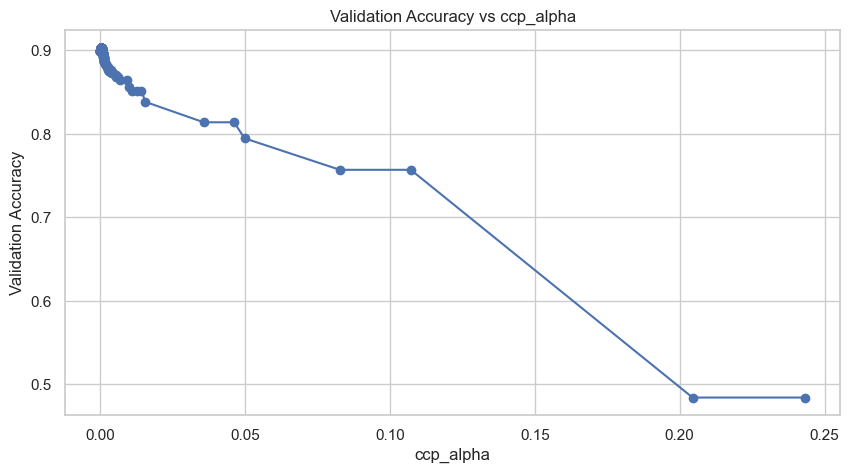

In [36]:
# Plot validation accuracy vs ccp_alpha
 
plt.figure(figsize=(10, 5))
plt.plot(alphas_to_try, val_scores, marker='o')
plt.title('Validation Accuracy vs ccp_alpha')
plt.xlabel('ccp_alpha')
plt.ylabel('Validation Accuracy')
plt.show()


In [37]:
# Train final pruned model on full training data (train set)
 
dt_pruned = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=best_alpha,
    criterion=dt_tuned.criterion,
    max_depth=dt_tuned.max_depth,
    min_samples_split=dt_tuned.min_samples_split,
    min_samples_leaf=dt_tuned.min_samples_leaf
)
 
dt_pruned.fit(X_train_enc, y_train)
 
y_pred_pruned = dt_pruned.predict(X_test_enc)
 
print('Accuracy (Pruned):', accuracy_score(y_test, y_pred_pruned))
print('\nClassification Report (Pruned):\n')
print(classification_report(y_test, y_pred_pruned))

Accuracy (Pruned): 0.9023354564755839

Classification Report (Pruned):

              precision    recall  f1-score   support

        High       0.91      0.88      0.90      2067
         Low       0.89      0.87      0.88      2065
      Medium       0.90      0.93      0.92      3875

    accuracy                           0.90      8007
   macro avg       0.90      0.89      0.90      8007
weighted avg       0.90      0.90      0.90      8007



In [38]:
from sklearn.metrics import f1_score
 
results = []
 
# Baseline
results.append({
    'Model': 'Baseline Tree',
    'Accuracy': accuracy_score(y_test, y_pred_base),
    'Macro F1': f1_score(y_test, y_pred_base, average='macro')
})
 
# Tuned
results.append({
    'Model': 'Tuned Tree (GridSearch)',
    'Accuracy': accuracy_score(y_test, y_pred_tuned),
    'Macro F1': f1_score(y_test, y_pred_tuned, average='macro')
})
 
# Pruned
results.append({
    'Model': 'Pruned Tree (ccp_alpha)',
    'Accuracy': accuracy_score(y_test, y_pred_pruned),
    'Macro F1': f1_score(y_test, y_pred_pruned, average='macro')
})
 
pd.DataFrame(results).sort_values(by=['Macro F1', 'Accuracy'], ascending=False)


,Model,Accuracy,Macro F1
1,Tuned Tree (GridSearch),0.902335,0.897715
2,Pruned Tree (ccp_alpha),0.902335,0.897626
0,Baseline Tree,0.833521,0.824556


In [39]:
# Identify columns by type
 
categorical_features = ['Gender', 'Location', 'GameGenre', 'GameDifficulty']
numeric_features = [
    'Age', 'PlayTimeHours', 'InGamePurchases', 'SessionsPerWeek',
    'AvgSessionDurationMinutes', 'PlayerLevel', 'AchievementsUnlocked'
]
 
preprocess = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', 'passthrough', numeric_features)
    ]
)
 
# Use the pruned model's important hyperparameters in the pipeline
pipeline_model = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', DecisionTreeClassifier(
        random_state=42,
        criterion=dt_pruned.criterion,
        max_depth=dt_pruned.max_depth,
        min_samples_split=dt_pruned.min_samples_split,
        min_samples_leaf=dt_pruned.min_samples_leaf,
        ccp_alpha=dt_pruned.ccp_alpha
    ))
])
 
pipeline_model

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [40]:
# Fit pipeline on raw (non-encoded) data
 
pipeline_model.fit(X_train, y_train)
 
y_pred_pipe = pipeline_model.predict(X_test)
 
print('Accuracy (Pipeline):', accuracy_score(y_test, y_pred_pipe))
print('\nClassification Report (Pipeline):\n')
print(classification_report(y_test, y_pred_pipe))

Accuracy (Pipeline): 0.9023354564755839

Classification Report (Pipeline):

              precision    recall  f1-score   support

        High       0.91      0.88      0.90      2067
         Low       0.89      0.87      0.88      2065
      Medium       0.90      0.93      0.92      3875

    accuracy                           0.90      8007
   macro avg       0.90      0.89      0.90      8007
weighted avg       0.90      0.90      0.90      8007



In [43]:
# Save the pipeline (model + preprocessing) for later use
 
MODEL_PATH = 'final_engagement_tree_pipeline.joblib'
joblib.dump(pipeline_model, MODEL_PATH)
print('Saved pipeline to:', MODEL_PATH)

Saved pipeline to: final_engagement_tree_pipeline.joblib


In [42]:
import os
os.getcwd()

'C:\\Users\\riaka\\Downloads'

In [44]:
loaded_model = joblib.load(MODEL_PATH)

sample_player = pd.DataFrame([{
    'Age': 26,
    'Gender': 'Male',
    'Location': 'USA',
    'GameGenre': 'Action',
    'PlayTimeHours': 7.5,
    'InGamePurchases': 1,
    'GameDifficulty': 'Medium',
    'SessionsPerWeek': 10,
    'AvgSessionDurationMinutes': 90,
    'PlayerLevel': 22,
    'AchievementsUnlocked': 15
}])

loaded_model.predict(sample_player)

array(['Medium'], dtype=object)